# [Lab Session 2](otsu.ipynb)

In [2]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 1.1.]()** Load the image:

In [3]:
imgf = plt.imread('data/NIH3T3/im/dna-0.png')
plt.figure()
plt.imshow(imgf)
plt.colorbar()

**[Task 1.2.]()** Quantify the image into 256 bins:

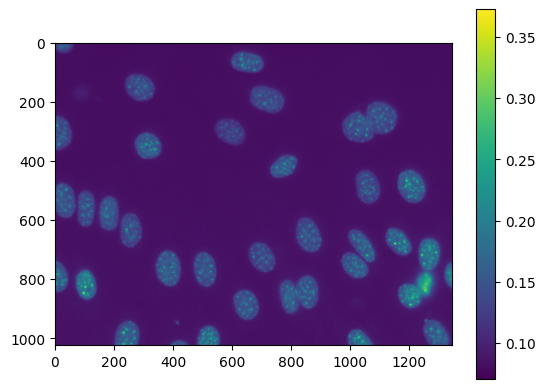

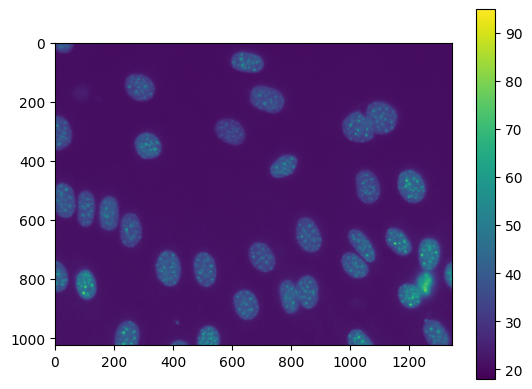

In [4]:
img8 = (imgf*255).round().astype(np.uint8)
plt.figure()
plt.imshow(img8)
plt.colorbar()

**[Task 1.3.]()** Compute the image histogram:

In [5]:
h = np.zeros(256)
for i in range (0,255):
    j = np.array(img8 == i).sum()
    h[i]=j
print(h)

[0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00 0.00000e+00
 1.00000e+00 1.38400e+03 1.25478e+05 5.50322e+05 3.44173e+05 7.58140e+04
 2.48010e+04 1.36310e+04 9.13900e+03 7.39000e+03 6.74300e+03 6.93000e+03
 7.92500e+03 9.88700e+03 1.23170e+04 1.46320e+04 1.61230e+04 1.74000e+04
 1.75300e+04 1.67810e+04 1.49330e+04 1.31710e+04 1.09560e+04 8.97200e+03
 7.37900e+03 6.16300e+03 5.23700e+03 4.49100e+03 3.96200e+03 3.38200e+03
 2.84100e+03 2.50500e+03 2.06900e+03 1.77900e+03 1.39700e+03 1.19400e+03
 1.01200e+03 8.85000e+02 7.33000e+02 6.39000e+02 5.54000e+02 5.18000e+02
 4.19000e+02 3.71000e+02 3.02000e+02 2.62000e+02 2.59000e+02 2.05000e+02
 1.67000e+02 1.55000e+02 1.45000e+02 1.18000e+02 1.00000e+02 1.03000e+02
 7.30000e+01 8.70000e+01 6.50000e+01 5.40000e+01 4.20000e+01 3.50000e+01
 2.20000e+01 2.30000e+01 1.40000e+01 1.30000e+01 7.

Show the computed histogram:

<BarContainer object of 256 artists>

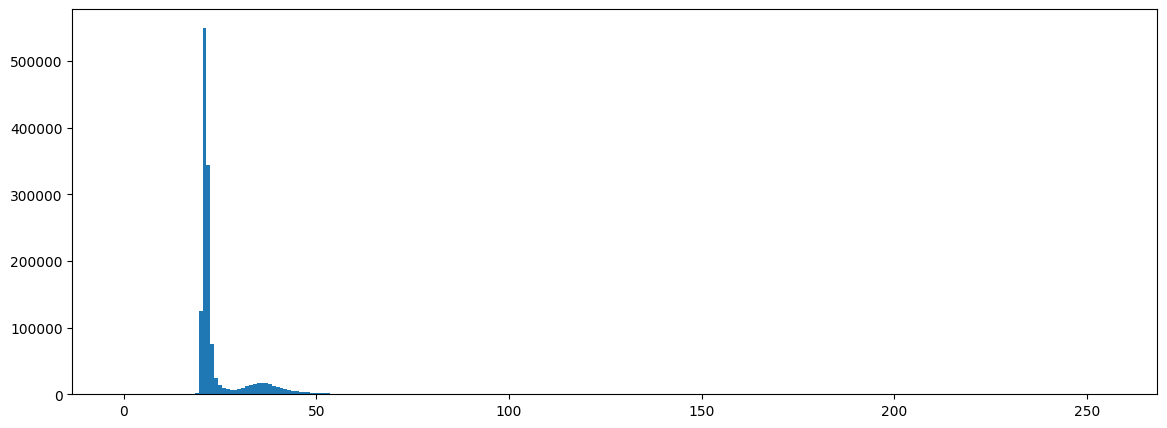

In [6]:
plt.figure(figsize=(14,5))
plt.bar(range(256), h, width=1)

**[Task 1.4.]()** Implement the method of Otsu:

In [7]:
list_T = []
for t in range (1,255):
    T = h[:t].sum()*np.var(h[:t])+h[t:].sum()*np.var(h[t:])
    list_T.append(T)
threshold = list_T.index(min(list_T))+1

print(threshold)

21


**[Task 1.5.]()** Perform Otsu thresholding:

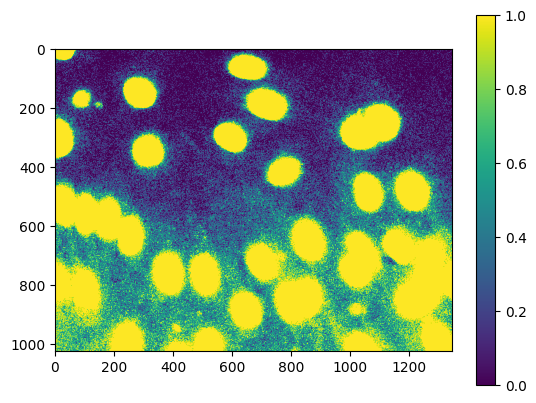

In [8]:
img_out = np.array(img8 > threshold)

plt.figure()
plt.imshow(img_out.astype(np.uint8))
plt.colorbar()

**[Task 1.6.]()** Compute the Dice coefficient:

In [9]:
groundtruth = plt.imread('data/NIH3T3/gt/0.png')
G = groundtruth.astype(np.uint8)
H = img_out.astype(np.uint8)

dice = (2*(G*H).sum())/(G.sum() + H.sum())
print(dice)

0.5257864791797588
